# Clúster de Usuarios de Tarjetas de Crédito

En este cuaderno de trabajo, nuestro objetivo principal es agrupar a los usuarios de tarjetas de crédito en diferentes segmentos o grupos, con el fin de identificar patrones de comportamiento significativos que puedan resultar útiles para análisis de negocio, personalización de servicios o gestión de riesgos.

Para ello, utilizaremos la técnica de Análisis de Componentes Principales (PCA), la cual nos permitirá reducir la dimensionalidad del conjunto de datos, es decir, condensar la información más relevante de múltiples variables en menos dimensiones sin perder demasiada información.

Una vez reducido el espacio de características, aplicaremos el algoritmo de K-medias (K-means), un método de aprendizaje no supervisado ampliamente utilizado para realizar tareas de clustering o agrupamiento. Este algoritmo se encargará de clasificar a los usuarios en distintos grupos según su similitud en el comportamiento financiero reflejado en los datos.

Al finalizar este proceso, analizaremos los resultados para ver si los grupos formados tienen sentido desde el punto de vista comercial o analítico, lo que puede facilitar la toma de decisiones estratégicas en productos financieros, segmentación de clientes, campañas de mercadeo, entre otros usos.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
ccData = pd.read_csv("/content/drive/MyDrive/ACP_y_Kmeans/CC GENERAL.csv")
print("Rows :", ccData.shape[0])
print("Columns :", ccData.shape[1])
ccData.head()

Rows : 8950
Columns : 18


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## Descripcción de la data

| Variable                          | Descripción                                                                 | Tipo de dato     |
|-----------------------------------|-----------------------------------------------------------------------------|------------------|
| CUST_ID                           | Identificador único del cliente (clave primaria).                          | Categórica (ID)  |
| BALANCE                           | Saldo promedio mensual del cliente.                                        | Cuantitativa     |
| BALANCE_FREQUENCY                 | Frecuencia con la que el saldo fue actualizado (valor entre 0 y 1).        | Cuantitativa     |
| PURCHASES                         | Valor total de compras realizadas.                                         | Cuantitativa     |
| ONEOFF_PURCHASES                  | Total de compras hechas en un solo pago.                                   | Cuantitativa     |
| INSTALLMENTS_PURCHASES           | Total de compras pagadas en cuotas o plazos.                               | Cuantitativa     |
| CASH_ADVANCE                      | Total de avances de efectivo realizados por el cliente.                    | Cuantitativa     |
| PURCHASES_FREQUENCY               | Frecuencia de compras en el periodo (valor entre 0 y 1).                   | Cuantitativa     |
| ONEOFF_PURCHASES_FREQUENCY       | Frecuencia de compras de un solo pago (valor entre 0 y 1).                 | Cuantitativa     |
| PURCHASES_INSTALLMENTS_FREQUENCY | Frecuencia de compras en cuotas (valor entre 0 y 1).                       | Cuantitativa     |
| CASH_ADVANCE_FREQUENCY           | Frecuencia de avances de efectivo (valor entre 0 y 1).                     | Cuantitativa     |
| CASH_ADVANCE_TRX                 | Número de transacciones de avance de efectivo realizadas.                  | Cuantitativa     |
| PURCHASES_TRX                     | Número de transacciones de compra realizadas.                              | Cuantitativa     |
| CREDIT_LIMIT                      | Límite de crédito asignado al cliente.                                     | Cuantitativa     |
| PAYMENTS                          | Total de pagos realizados por el cliente.                                  | Cuantitativa     |
| MINIMUM_PAYMENTS                  | Valor mínimo de pagos realizados.                                          | Cuantitativa     |
| PRC_FULL_PAYMENT                  | Porcentaje de veces que el cliente pagó el total de su deuda (0 a 1).      | Cuantitativa     |
| TENURE                            | Número de meses en que el cliente ha sido titular de la tarjeta.           | Cuantitativa     |


## Preprocesamiento del Conjunto de Datos

### Primera Exploración

El conjunto de datos contiene 8.950 registros (filas) y 18 atributos (columnas) en cada uno. Dado que se trata de un problema de aprendizaje no supervisado, no contamos con una variable objetivo o de respuesta, como suele suceder en problemas de clasificación o regresión.

Un aspecto importante a tener en cuenta desde el inicio es que la columna CUST\_ID (Identificador del Cliente) puede eliminarse, ya que su única función es actuar como clave primaria, es decir, un identificador único para cada observación. Esta columna no aporta información útil para el análisis de patrones o el agrupamiento, ya que no representa una característica inherente al comportamiento del cliente.

Posteriormente, cuando apliquemos el Análisis de Componentes Principales (PCA), identificaremos cuáles atributos o combinaciones de atributos son más relevantes para explicar la variabilidad en los datos. Una vez detectados, nos enfocaremos en describir en detalle únicamente los atributos más significativos, es decir, aquellos que realmente influyen en la segmentación de usuarios.

No es necesario hacer un análisis detallado de cada una de las 18 variables desde el comienzo, ya que no todas serán utilizadas en el modelo de agrupamiento. Este enfoque nos permite trabajar de forma más eficiente, concentrándonos en las variables con mayor valor explicativo y evitando la sobrecarga de información innecesaria para los fines del análisis.


In [5]:
#Se elimina "CUST_ID" de la base de datos
ccData = ccData.drop("CUST_ID", axis=1)


### Valores Faltantes

A continuación, procedemos a **identificar si existen valores faltantes (missing values) en el conjunto de datos**, es decir, celdas vacías o datos ausentes en algunas de las variables.

La presencia de valores faltantes es un aspecto crítico en el preprocesamiento de datos, ya que puede afectar la calidad del análisis y el rendimiento de los modelos de aprendizaje automático. Una vez detectados estos valores, **aplicaremos las estrategias adecuadas para tratarlos**, las cuales pueden incluir:

* Eliminación de filas o columnas con valores faltantes (cuando la cantidad sea mínima y no impacte el análisis).
* Imputación o reemplazo de los valores ausentes con medidas estadísticas como la media, mediana o moda.
* Uso de métodos más sofisticados como la imputación basada en modelos.

La estrategia a utilizar dependerá del **tipo de variable**, de la **proporción de datos faltantes** y de la **importancia de la variable** en el análisis que se va a realizar.


In [6]:
ccData.isna().sum()

,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0
CASH_ADVANCE_FREQUENCY,0


Observamos que hay un valor nulo en la columna CREDIT\_LIMIT y 313 valores nulos en la columna MINIMUM\_PAYMENTS. Antes de proceder a rellenar estos valores ausentes, es importante comprender qué representa cada uno de estos atributos y cuál podría ser la causa de la ausencia de datos.

1. En el caso de la variable MINIMUM\_PAYMENTS, cuando su valor es nulo, se puede asumir razonablemente que el cliente no realizó ningún pago mínimo durante ese periodo. Por lo tanto, tiene sentido reemplazar los valores nulos por cero, ya que esto indicaría explícitamente que no hubo ningún pago registrado como mínimo.

2. Para la variable CREDIT\_LIMIT, si el valor es nulo, una interpretación lógica es que ese cliente no tiene un límite de crédito asignado o que no estaba disponible en el momento de la recolección de los datos. En este caso, también se puede establecer el valor en cero, ya que refleja la ausencia de una línea de crédito definida para dicho usuario.

Es importante tener en cuenta que estas decisiones deben ser respaldadas por el conocimiento del dominio o por supuestos razonables basados en el comportamiento financiero. Aunque establecer estos valores en cero puede facilitar el análisis y evitar errores computacionales, también conviene documentar claramente este tratamiento, ya que puede influir en la interpretación de los resultados posteriores.

In [7]:
ccData = ccData.fillna(0)

### Estandarización y Normalización

Antes de aplicar el Análisis de Componentes Principales (PCA), es fundamental **estandarizar y normalizar los datos**. Este paso es clave en el preprocesamiento, especialmente cuando se utilizan técnicas que dependen de la escala de las variables.

Además, dado que el algoritmo de agrupamiento que se empleará posteriormente (como K-means) se basa en la **distancia entre puntos de datos en el espacio multidimensional**, es importante que todas las variables contribuyan de manera equitativa. Si algunas variables tienen magnitudes o unidades mucho mayores que otras (por ejemplo, montos en dólares frente a proporciones entre 0 y 1), podrían dominar el cálculo de distancias, generando **agrupamientos distorsionados o poco representativos**.

La **estandarización** consiste en transformar los datos para que tengan una media de 0 y una desviación estándar de 1, lo que asegura que todas las variables estén en una escala comparable. Por otro lado, la **normalización** suele referirse a la transformación de los datos para que se encuentren en un rango definido, generalmente entre 0 y 1, aunque el término puede variar según el contexto.

Realizar este paso correctamente mejora significativamente el rendimiento tanto del PCA como del algoritmo de clustering, ya que permite que ambos enfoquen su análisis en la forma y estructura de los datos, y no en diferencias artificiales de escala.


In [8]:
scaler = StandardScaler()
scaled_ccData = scaler.fit_transform(ccData)
norm_ccData = normalize(scaled_ccData)

## Análisis de Componentes Principales (PCA)

Utilizamos el Análisis de Componentes Principales (PCA) para reducir la dimensionalidad de nuestros datos. En términos prácticos, esto significa transformar nuestro conjunto original de 17 variables en un número menor de componentes principales, conservando la mayor cantidad posible de la información contenida en los datos originales.

El objetivo del PCA es simplificar la estructura del conjunto de datos, eliminando redundancias y correlaciones entre variables, lo cual facilita su interpretación y análisis. Esta reducción es especialmente útil en tareas de aprendizaje no supervisado, como el clustering, ya que los métodos de agrupamiento suelen verse afectados negativamente por la "maldición de la dimensionalidad". Este fenómeno ocurre cuando el número de dimensiones (o variables) es muy alto, lo que puede provocar que las distancias entre los puntos de datos se vuelvan menos significativas y, en consecuencia, degrade el rendimiento de los algoritmos de agrupamiento.

Al aplicar PCA, no solo reducimos la complejidad del conjunto de datos, sino que también ayudamos a mejorar la eficiencia computacional y la capacidad del algoritmo para identificar patrones reales y bien definidos en los datos.

In [9]:
pca = PCA()
pca.fit(norm_ccData)

PCA()

Text(0, 0.5, 'Varianza Explicada Acumulada')

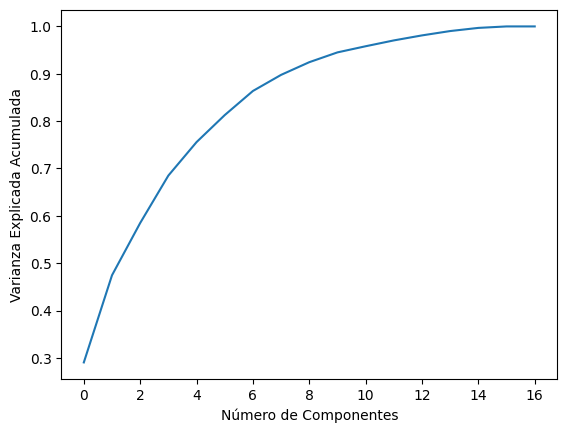

In [10]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Acumulada')

In [11]:
np.cumsum(pca.explained_variance_ratio_)

array([0.29044997, 0.47452947, 0.58490237, 0.68505818, 0.75571567,
       0.8127604 , 0.86368729, 0.89770753, 0.92447857, 0.94517107,
       0.95813186, 0.97045662, 0.9810481 , 0.99022739, 0.99688251,
       0.9999988 , 1.        ])

### Contribuciones del PCA


### Resumen del PCA

La gráfica anterior muestra la **varianza explicada acumulada** en función del número de componentes principales utilizadas. En nuestro caso, seleccionaremos **2 componentes principales**.

Estas dos primeras componentes explican aproximadamente el **47,5 % de la variabilidad total** presente en los datos originales. Aunque utilizar **4 o 5 componentes** permitiría capturar un mayor porcentaje de la varianza y, por tanto, describir mejor la estructura subyacente de los datos, optamos por trabajar con solo 2 componentes para **facilitar la visualización del agrupamiento** (clustering) en un plano bidimensional.

Este compromiso entre representatividad y visualización es común en análisis exploratorios, donde el objetivo es comprender patrones generales y no necesariamente optimizar la retención total de la información.


In [12]:
n_components=2
pca_final = PCA(n_components=n_components)
pca_final.fit(norm_ccData)
pca_ccData = pca_final.fit_transform(norm_ccData)

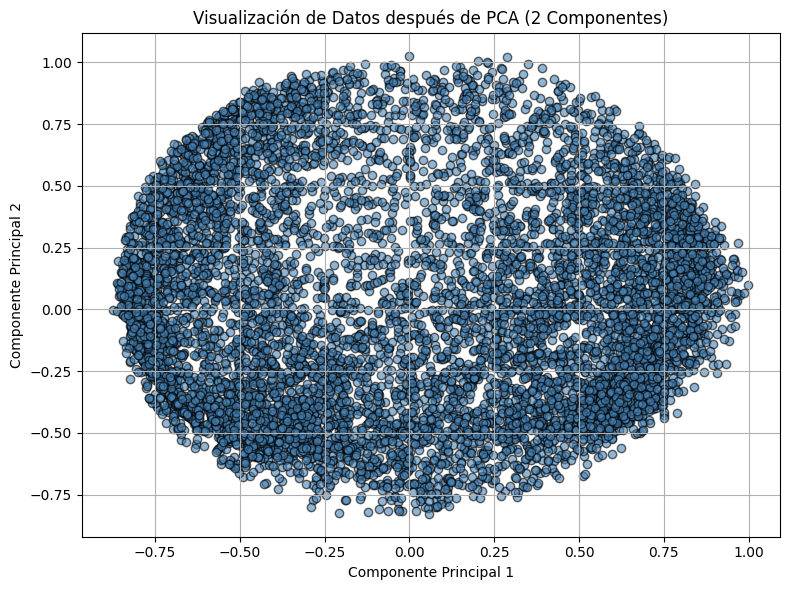

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(pca_ccData[:, 0], pca_ccData[:, 1], c='steelblue', alpha=0.6, edgecolors='k')
plt.title('Visualización de Datos después de PCA (2 Componentes)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.tight_layout()
plt.show()

### Visualización de los Datos Reducidos

Una vez que visualizamos los datos en el nuevo espacio bidimensional generado por el Análisis de Componentes Principales (PCA), **no se observan patrones evidentes de forma inmediata**. Es decir, a simple vista no se identifican agrupamientos o estructuras claras entre los puntos proyectados.

Esto es común en los primeros pasos del análisis exploratorio, especialmente cuando se trabaja con datos reales que pueden ser complejos o tener relaciones no lineales. La reducción a dos dimensiones ayuda a simplificar la visualización, pero también puede implicar la pérdida de información que podría ser importante para identificar patrones más sutiles.

A continuación, el siguiente paso consiste en **interpretar qué representan realmente estas componentes principales**, es decir, entender qué combinación de variables originales está influenciando más a cada componente. Esta interpretación nos permitirá contextualizar mejor la distribución de los datos en el espacio reducido y facilitará la posterior identificación de clústeres o comportamientos similares entre los usuarios.



In [14]:
for i in np.arange(n_components):
    index =  np.argmax(np.absolute(pca_final.get_covariance()[i]))
    max_cov = pca_final.get_covariance()[i][index]
    column = ccData.columns[index]
    print("Componente Principal", i+1, "maxima covarianza :", "{:.2f}".format(max_cov), "columna", column)

Componente Principal 1 maxima covarianza : 0.06 columna BALANCE
Componente Principal 2 maxima covarianza : 0.04 columna BALANCE_FREQUENCY


### Interpretación del PCA

Dado que las **componentes principales son combinaciones lineales de las variables originales**, lo que buscamos ahora es identificar **qué variables influyen más en cada componente principal**. Específicamente, analizamos la **matriz de covarianza** generada por el PCA para determinar qué atributos presentan la mayor covarianza con cada componente.

1. En el caso de la **primera componente principal**, la variable que tiene mayor covarianza es **BALANCE**. Por lo tanto, podemos interpretar que esta componente está fuertemente relacionada con el **saldo promedio disponible en la cuenta del cliente para realizar compras**. En este contexto, la primera componente puede verse como un eje que representa el nivel de balance o disponibilidad financiera del cliente.

2. En cuanto a la **segunda componente principal**, la variable con mayor covarianza es **BALANCE\_FREQUENCY**. Esto indica que esta componente refleja principalmente la **frecuencia con la que se actualiza el saldo del cliente**, es decir, con qué regularidad se registran movimientos o actualizaciones en su cuenta. Así, la segunda componente puede interpretarse como una medida del comportamiento transaccional o la actividad financiera del cliente.

Esta interpretación es útil porque **nos permite dar sentido a los ejes del espacio reducido**, lo que facilita tanto la visualización como la comprensión de los agrupamientos posteriores.



### Contribucion de Variables

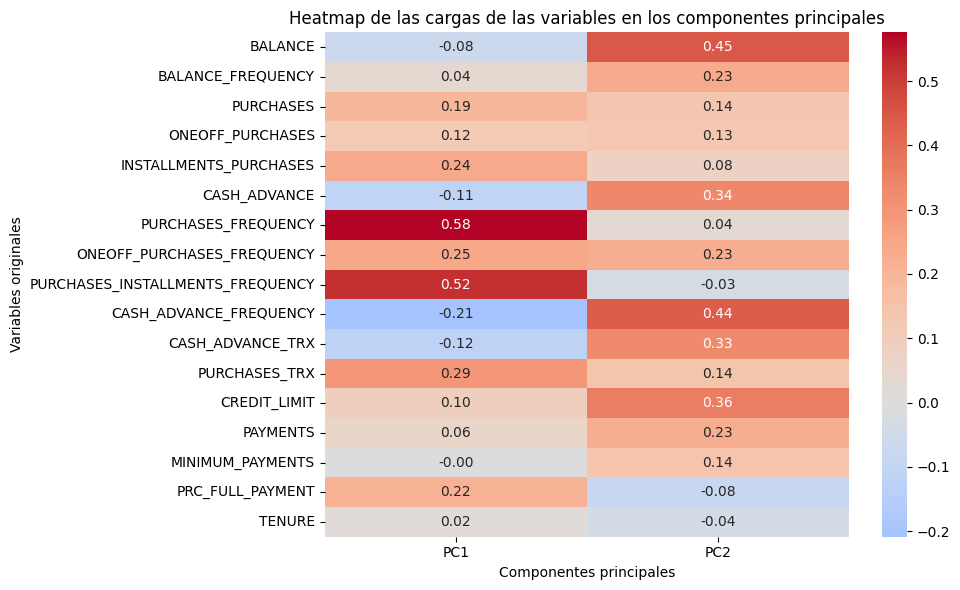

In [15]:
loadings = pd.DataFrame(
    pca_final.components_.T,
    columns=[f'PC{i+1}' for i in range(pca_final.n_components_)],
    index=ccData.columns
)

# Crear el heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Heatmap de las cargas de las variables en los componentes principales')
plt.xlabel('Componentes principales')
plt.ylabel('Variables originales')
plt.tight_layout()
plt.show()

**Componente Principal 1 (PC1):**
Este componente está fuertemente definido por variables relacionadas con la frecuencia de compra. Por ejemplo, la variable `PURCHASES_FREQUENCY` tiene una carga de 0.58, la más alta y positiva, indicando que cuanto mayor sea la frecuencia de compras, más se incrementa el valor de PC1. Similarmente, `PURCHASES_INSTALLMENTS_FREQUENCY` (0.52) y `PURCHASES_TRX` (0.29) también contribuyen notablemente, mostrando que PC1 representa clientes con alta actividad en compras, tanto en montos como en número de transacciones. En contraste, variables asociadas a adelantos de efectivo (`CASH_ADVANCE_FREQUENCY` con -0.21 y `CASH_ADVANCE` con -0.11) tienen cargas negativas, lo que implica que un cliente con un valor alto en PC1 tiende a tener baja frecuencia y monto en adelantos. El saldo (`BALANCE`) también tiene carga negativa leve (-0.08), indicando que altos valores de PC1 se asocian a saldos relativamente bajos o controlados. En resumen, PC1 mide un eje donde los clientes se diferencian entre quienes usan activamente la tarjeta para compras frecuentes y quienes no.

---

**Componente Principal 2 (PC2):**
En PC2, las cargas positivas más destacadas corresponden a `BALANCE` (0.45), `CASH_ADVANCE_FREQUENCY` (0.44), y `CREDIT_LIMIT` (0.36). Esto indica que este componente refleja a clientes con saldos elevados, uso frecuente de adelantos de efectivo y mayores límites de crédito. Por ejemplo, un valor alto en PC2 sugiere que el cliente tiende a mantener saldos altos y utiliza regularmente adelantos, lo que puede reflejar un perfil más endeudado o activo en el manejo del crédito. Además, `CASH_ADVANCE` (0.34) y `CASH_ADVANCE_TRX` (0.33) también apoyan esta interpretación, mostrando que no solo la frecuencia, sino también el monto y número de transacciones de adelanto afectan positivamente este componente. Variables como `BALANCE_FREQUENCY` (0.23) y `PAYMENTS` (0.23) también cargan positivamente, lo que indica que clientes con alta frecuencia de saldo y pagos frecuentes también tienen valores altos en PC2. Por tanto, PC2 mide un eje que distingue a clientes por su nivel de endeudamiento y actividad en movimientos de efectivo, diferenciando a quienes manejan mayor deuda y crédito.


---

### Agrupamiento con K-means

Recordemos que el algoritmo **K-means** requiere que especifiquemos previamente **el número de clústeres (grupos)** en los que deseamos segmentar los datos. Como **no conocemos de antemano cuántos grupos son ideales**, adoptaremos una estrategia exploratoria: probaremos diferentes valores de *k*, específicamente en el rango de **2 a 11 clústeres**.

Posteriormente, analizaremos métricas gráficas como:

* La **inercia** (suma de distancias dentro de los clústeres),
* El **método del codo** (*elbow method*), y
* El **coeficiente de silueta** (*silhouette score*)

Estas métricas nos permitirán **evaluar la calidad del agrupamiento** para cada valor de *k* y seleccionar el número óptimo de clústeres que mejor represente la estructura de los datos.


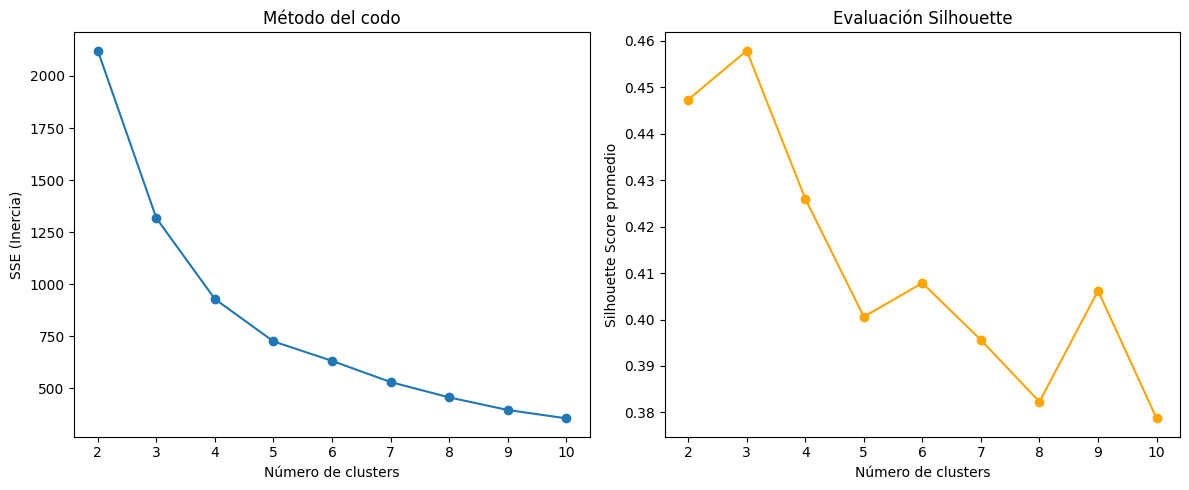

In [16]:
sse = {}
silhouette_scores = {}
n_clust = np.arange(2, 11)

for k in n_clust:
    kmeans = KMeans(n_clusters=k, random_state=0)
    cluster_labels = kmeans.fit_predict(pca_ccData)
    sse[k] = kmeans.inertia_
    silhouette_scores[k] = silhouette_score(pca_ccData, cluster_labels)

# Graficar SSE (elbow)
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(list(sse.keys()), list(sse.values()), marker='o')
plt.xlabel('Número de clusters')
plt.ylabel('SSE (Inercia)')
plt.title('Método del codo')

# Graficar Silhouette Score
plt.subplot(1,2,2)
plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker='o', color='orange')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score promedio')
plt.title('Evaluación Silhouette')

plt.tight_layout()
plt.show()


**Método del codo:**
El gráfico del método del codo muestra cómo la suma de errores cuadráticos dentro de los clusters (SSE) disminuye rápidamente al aumentar el número de clusters desde 2 hasta alrededor de 3 o 4. Después de este punto, la reducción en SSE se vuelve mucho menos pronunciada, formando una curva que se “dobla” o “hace codo”. Esto indica que agregar más clusters después de 3 o 4 aporta una mejora marginal en la compactación de los grupos. Por lo tanto, este método sugiere que el número óptimo de clusters para el conjunto de datos está cerca de 3 o 4.

---

**Evaluación Silhouette:**
El gráfico de la evaluación Silhouette mide qué tan bien definidos y separados están los clusters para diferentes números de grupos. En este caso, el valor promedio del Silhouette Score es más alto para 3 clusters, alcanzando aproximadamente 0.46, lo que indica que con 3 clusters los grupos son más coherentes y están mejor separados entre sí. A medida que se aumenta el número de clusters más allá de 3, el Silhouette Score disminuye, señalando que los clusters adicionales generan agrupaciones menos claras o más solapadas. Por tanto, este análisis también apoya la elección de 3 clusters como la mejor opción.


### Resumen del Agrupamiento con K-means

En la gráfica anterior estamos aplicando el **método del codo** (*elbow method*), que consiste en **identificar visualmente el punto óptimo** en el cual aumentar el número de clústeres ya no genera una mejora significativa en la métrica de inercia. Este punto, denominado "el codo", indica que **agregar más clústeres después de ese valor aporta beneficios marginales o nulos en la compactación de los grupos**.

La **inercia** que se observa en el eje vertical representa la **suma de los cuadrados de las distancias internas a los clústeres** (*within-cluster sum of squares*). Es una medida de qué tan compactos y cohesivos son los grupos formados: **una inercia más baja indica clústeres más compactos y homogéneos internamente**.

A partir del gráfico, se puede observar que con **3 clústeres se alcanza un buen equilibrio**: la inercia disminuye notablemente hasta ese punto, y luego las reducciones adicionales son más pequeñas. Aunque técnicamente el uso de **10 clústeres** proporciona la **menor inercia total**, esto **complicaría la interpretación de los resultados** y probablemente **no aporte un significado práctico adicional**, especialmente si los clústeres se vuelven demasiado específicos o difíciles de distinguir conceptualmente.

Por tanto, seleccionar 3 clústeres parece ser una **opción razonable desde el punto de vista analítico y de interpretabilidad**, lo que permite segmentar adecuadamente a los usuarios sin perder claridad en los hallazgos.


In [17]:
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(pca_ccData)

KMeans(n_clusters=3, random_state=0)

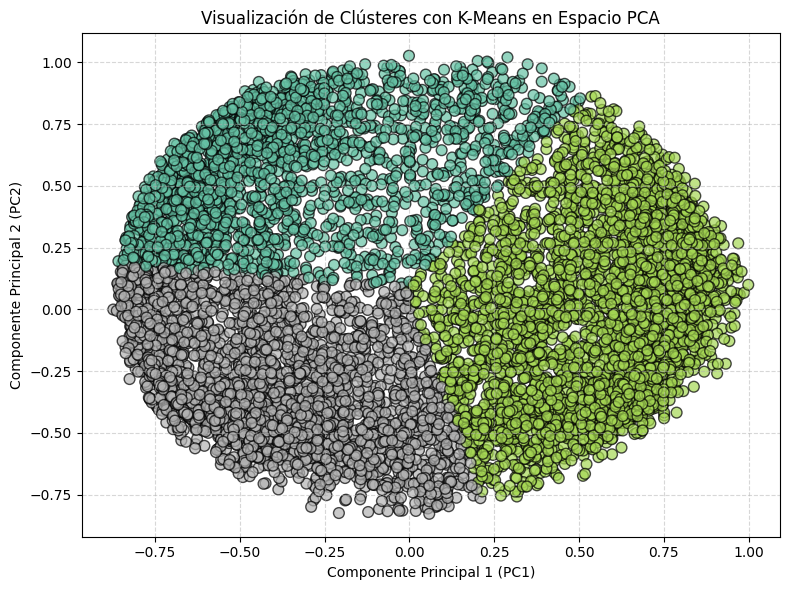

In [18]:
kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(pca_ccData)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    pca_ccData[:, 0],
    pca_ccData[:, 1],
    c=labels,
    cmap='Set2',
    edgecolor='k',
    alpha=0.7,
    s=60
)

# Etiquetas y título
plt.xlabel("Componente Principal 1 (PC1)")
plt.ylabel("Componente Principal 2 (PC2)")
plt.title("Visualización de Clústeres con K-Means en Espacio PCA")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Visualización de los Clústeres

La visualización actual muestra que **los tres clústeres identificados están claramente separados** en el espacio reducido mediante PCA. Esto indica que el algoritmo de K-means logró segmentar a los usuarios de tarjetas de crédito en grupos bien diferenciados en función de sus características financieras principales.

Para enriquecer aún más esta representación gráfica, **vamos a extender la visualización incluyendo los límites de decisión** (*decision boundaries*). Estos límites nos permitirán observar **cómo el espacio se ha dividido en regiones según la cercanía de los puntos a los centroides de cada clúster**. En otras palabras, podremos ver de forma visual qué zona del espacio pertenece a qué grupo, lo que facilita la interpretación del modelo y su capacidad para discriminar entre diferentes perfiles de usuarios.

La incorporación de los límites de decisión es especialmente útil para:

* Evaluar qué tan claramente separados están los clústeres.
* Visualizar zonas de transición o superposición entre grupos.
* Comunicar de forma intuitiva los resultados del agrupamiento a audiencias no técnicas.


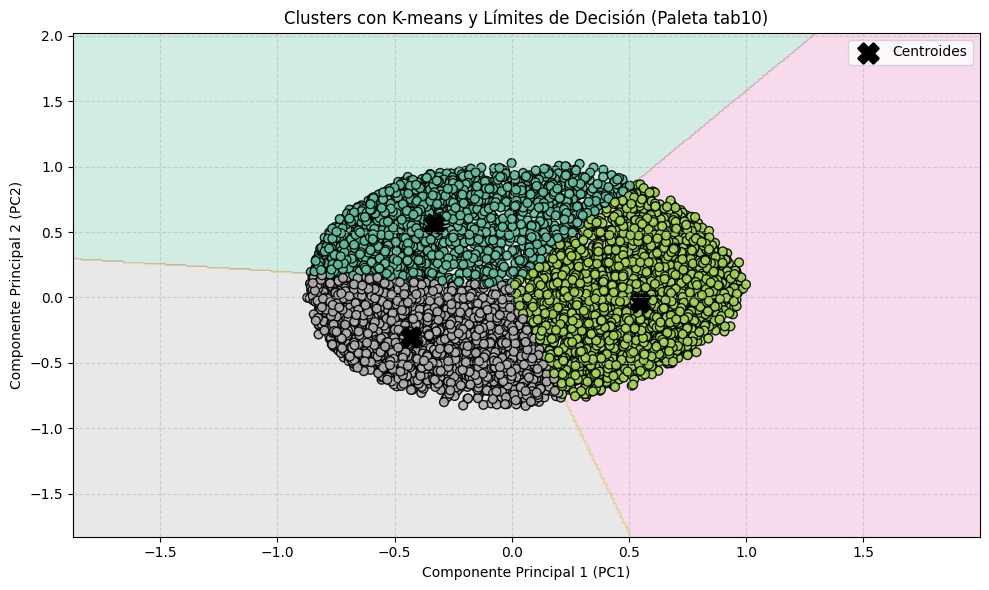

In [22]:
h = 0.01

# Límites del gráfico
x_min, x_max = pca_ccData[:, 0].min() - 1, pca_ccData[:, 0].max() + 1
y_min, y_max = pca_ccData[:, 1].min() - 1, pca_ccData[:, 1].max() + 1

# Malla de puntos para predecir
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = kmeans.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Crear figura
plt.figure(figsize=(10, 6))

# Fronteras de decisión con nueva paleta de colores
plt.contourf(xx, yy, Z, cmap='Set2', alpha=0.3)

# Puntos originales coloreados por clúster
plt.scatter(pca_ccData[:, 0], pca_ccData[:, 1],
            c=labels, cmap='Set2', edgecolor='k', s=40, alpha=0.9)

# Centroides resaltados
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker='X', s=200, linewidths=2,
            color='black', label='Centroides')

# Personalización del gráfico
plt.xlabel("Componente Principal 1 (PC1)")
plt.ylabel("Componente Principal 2 (PC2)")
plt.title("Clusters con K-means y Límites de Decisión (Paleta tab10)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Ahora la **frontera de decisión** entre los clústeres es mucho más clara gracias a la visualización. Podemos observar con mayor precisión **cómo se ha dividido el espacio** en función de la proximidad de los puntos a los centroides, así como la **ubicación de los centros de los tres clústeres identificados** mediante el algoritmo K-means.

Estos centroides representan los **puntos medios o promedios de cada grupo** en el espacio de las componentes principales. En otras palabras, son representaciones típicas del comportamiento financiero de los usuarios dentro de cada clúster.

Nuestro objetivo final en este análisis es **interpretar el significado de cada clúster**, es decir, entender **qué tipo de usuarios de tarjeta de crédito** agrupa cada uno. Para lograrlo, debemos regresar al espacio original de variables (antes del PCA) y analizar las características promedio de los usuarios dentro de cada grupo.

Este paso es crucial porque nos permitirá:

* Asignar etiquetas o descripciones a cada clúster (por ejemplo: “clientes con alto gasto y pagos completos”, “clientes inactivos”, etc.).
* Derivar conclusiones útiles para la toma de decisiones en áreas como marketing, gestión de riesgo o personalización de productos financieros.
* Validar si los grupos son coherentes y accionables desde un punto de vista estratégico.


In [23]:
for i in np.arange(len(centroids)):
    print("Centroide del Clúster", i+1, ":", centroids[i])

Centroide del Clúster 1 : [-0.33289387  0.55961967]
Centroide del Clúster 2 : [ 0.54576364 -0.03610856]
Centroide del Clúster 3 : [-0.42817993 -0.29874383]


## Interpretación y Conclusiones

Al interpretar las **componentes principales** generadas por el Análisis de Componentes Principales (PCA), debemos tener en cuenta que dichas interpretaciones son **aproximadas** y solo ofrecen una **idea general del comportamiento de los datos en relación con las variables originales**. Es importante aclarar que **no podemos equiparar directamente las componentes con atributos individuales**, ya que cada componente es una combinación lineal de múltiples variables. Por tanto, lo que podemos hacer es describir **cómo se comporta cada componente en función de las variables que más influyen en ella**.

Con esto en mente, pasamos a interpretar el significado de los tres clústeres identificados:

1. **Clúster 1 (Verde Oscuro)**
   El centro de este clúster se encuentra en las coordenadas (-0.42, -0.31) dentro del espacio PCA. De acuerdo con nuestra interpretación de las componentes principales, este grupo representa a **clientes con saldos relativamente bajos**, y cuyos **saldos se actualizan con poca frecuencia**. Este perfil puede corresponder a usuarios con poca actividad financiera o con bajo uso de la tarjeta de crédito.

2. **Clúster 2 (Verde Claro)**
   El centro de este clúster se sitúa en (0.54, -0.03). Este grupo representa a **clientes con saldos relativamente altos** y **frecuencias de actualización más elevadas** que los del Clúster 1. Esto sugiere un perfil de usuario más activo financieramente, que posiblemente realiza más compras y mantiene un mayor flujo de movimientos en su cuenta.

3. **Clúster 3 (Amarillo)**
   El centro de este clúster se ubica en (-0.35, 0.54). Aunque los clientes en este grupo también presentan **saldos bajos**, similares a los del Clúster 1, su comportamiento se diferencia significativamente en que **los saldos se actualizan con mayor frecuencia**. De hecho, este grupo tiene las actualizaciones de saldo **más frecuentes entre los tres**, lo que podría indicar un uso muy activo de la tarjeta, con operaciones de bajo monto pero alta recurrencia.
